# 02 假设检验：主指标、次要指标、分层、功效

**这份 notebook 的目标**：把"gate_30 比 gate_40 好 0.8pp"这句话，变成一个有区间、有前提、
有敏感性分析的结论，并回答"这个实验的设计够不够用"。

**路线图**

1. 主指标：两比例 z 检验 + 置信区间（先手算，再调库，确保懂公式）
2. 次要指标：次日留存、游戏局数（bootstrap），以及多重比较校正
3. 分层：按局数分桶，看效应是否一致，检查辛普森悖论
4. 功效：这次实验能检出多大的效应？下次要多少人？
5. 决策：改不改门槛，风险是什么

> 运行前提：`pip install -r requirements.txt`（pandas/numpy/scipy/matplotlib/statsmodels）。


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.stats_utils import (  # noqa: E402
    achieved_power,
    bonferroni,
    bootstrap_diff,
    diff_ci_newcombe,
    min_detectable_delta,
    required_sample_size,
    srm_check,
    two_proportion_test,
    wilson_interval,
)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 120)

df = pd.read_csv(ROOT / "data" / "raw" / "cookie_cats.csv")
for c in ["retention_1", "retention_7"]:
    df[c] = df[c].astype(int)

c = df[df.version == "gate_30"]
t = df[df.version == "gate_40"]
print("对照组", len(c), "实验组", len(t))


对照组 44700 实验组 45489


## 1. 主指标：7 日留存的两比例检验

**为什么用两比例 z 检验，而不是 t 检验？**

- 指标是 0/1（留存/未留存），样本比例近似正态，标准误有解析公式 `sqrt(p(1-p)/n)`；
- t 检验是为"连续变量的均值"设计的，用在这里虽然大样本下结果接近，但概念上不对；
- 两比例检验还能直接给出差值的置信区间，业务方要的是"差多少"，不是"p 小不小"。

**先手算一遍**，确认自己知道每个符号在干什么：

```
diff = p_control - p_treatment
SE_pooled = sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))   # 检验用（H0 下两组同比例）
z = diff / SE_pooled
p_value = 2 * (1 - Φ(|z|))                                 # 双侧
```


In [2]:
x1, n1 = int(c.retention_7.sum()), len(c)
x2, n2 = int(t.retention_7.sum()), len(t)
p1, p2 = x1 / n1, x2 / n2
diff = p1 - p2

p_pool = (x1 + x2) / (n1 + n2)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z_manual = diff / se_pool
p_manual = 2 * (1 - stats.norm.cdf(abs(z_manual)))

print(f"p1={p1:.4%}, p2={p2:.4%}, diff={diff*100:+.4f}pp")
print(f"手算: z={z_manual:.4f}, p={p_manual:.6f}")

res = two_proportion_test(x1, n1, x2, n2)
print("库函数:", res.summary())
print(f"差值校验: {abs(res.z - z_manual) < 1e-9}")


p1=19.0201%, p2=18.2000%, diff=+0.8201pp
手算: z=3.1644, p=0.001554
库函数: 对照 19.02% (n=44700) vs 实验 18.20% (n=45489); 绝对差 +0.820 pp, 95% CI [+0.312, +1.328] pp, 相对 +4.51%, p=0.0016
差值校验: True


手算和库函数对上了，说明公式没记错。注意两个标准误的区别：

- **检验**（算 z、p）用合并标准误 `SE_pooled`：零假设是"两组同比例"，合并才有意义；
- **置信区间**用非合并标准误 `SE_unpooled = sqrt(p1(1-p1)/n1 + p2(1-p2)/n2)`：
  区间描述的是"差值本身的抽样波动"，两组各自的比例都要估计。

这两个 SE 不一样大，是初学者最容易写错的地方之一。


In [3]:
se_unpooled = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
z_crit = stats.norm.ppf(0.975)
ci_low, ci_high = diff - z_crit * se_unpooled, diff + z_crit * se_unpooled

print(f"Wald 95% CI: [{ci_low*100:+.3f}, {ci_high*100:+.3f}] pp")
print(f"库函数 CI:   [{res.ci_low*100:+.3f}, {res.ci_high*100:+.3f}] pp")

# 稳健性：比例不极端时 Newcombe 和 Wald 应该几乎一样
nc = diff_ci_newcombe(x1, n1, x2, n2)
print(f"Newcombe 95% CI: [{nc[0]*100:+.3f}, {nc[1]*100:+.3f}] pp")

# 单组 Wilson 区间（画柱状图用）
for name, x, n in [("gate_30", x1, n1), ("gate_40", x2, n2)]:
    lo, hi = wilson_interval(x, n)
    print(f"{name}: {x/n:.2%} [{lo:.2%}, {hi:.2%}]")


Wald 95% CI: [+0.312, +1.328] pp
库函数 CI:   [+0.312, +1.328] pp
Newcombe 95% CI: [+0.312, +1.328] pp
gate_30: 19.02% [18.66%, 19.39%]
gate_40: 18.20% [17.85%, 18.56%]


**结论怎么读**：差值 +0.82pp，95% CI [+0.31, +1.33]pp。区间不含 0，等价于双侧 p<0.05；
区间的宽度告诉我们"真实提升大概率在 0.3 到 1.3pp 之间"——**业务决策要看下界够不够大**，
而不是只盯 p 值。Newcombe 区间与 Wald 几乎一致，说明结论不是区间方法造成的。


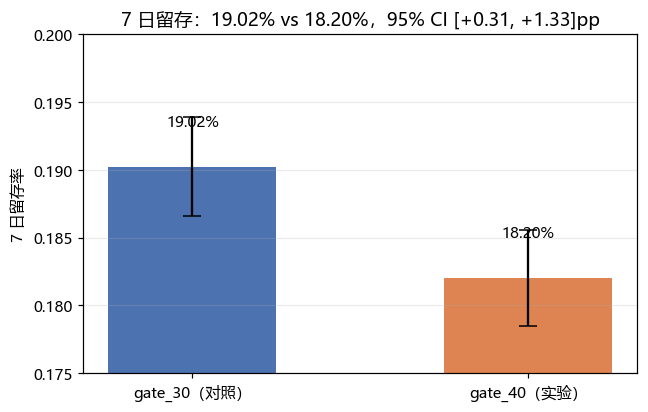

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
rates = [p1, p2]
cis = [wilson_interval(x1, n1), wilson_interval(x2, n2)]
errs = [[rates[i] - cis[i][0] for i in range(2)], [cis[i][1] - rates[i] for i in range(2)]]
bars = ax.bar(["gate_30（对照）", "gate_40（实验）"], rates, color=["#4C72B0", "#DD8452"],
              width=0.5, yerr=errs, capsize=6)
for b, v in zip(bars, rates):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.003, f"{v:.2%}", ha="center")
ax.set_ylim(0.175, 0.20)
ax.set_ylabel("7 日留存率")
ax.set_title("7 日留存：19.02% vs 18.20%，95% CI [+0.31, +1.33]pp")
ax.grid(axis="y", alpha=0.25)


## 2. 次要指标与多重比较

只看主指标是不够的：产品可能"把留存做上去了，但把体验做差了"。这里看两个次要指标：

- **次日留存**：短期体验有没有受损；
- **游戏局数**：参与度有没有变化（长尾，用中位数 + bootstrap）。

同时看多个指标，就要处理**多重比较**：测 5 个指标，每个都用 α=0.05，至少一个假阳性的概率会升到
`1-0.95^5 ≈ 23%`。最简单的修法是 Bonferroni：把阈值除以检验个数。


In [5]:
# 次日留存
x1d, x2d = int(c.retention_1.sum()), int(t.retention_1.sum())
d1 = two_proportion_test(x1d, n1, x2d, n2)
print("次日留存:", d1.summary())

# Bonferroni：主指标 + 次要指标一起校正
bon = bonferroni([res.p_value, d1.p_value])
print()
print(bon.summary())


次日留存: 对照 44.82% (n=44700) vs 实验 44.23% (n=45489); 绝对差 +0.591 pp, 95% CI [-0.058, +1.239] pp, 相对 +1.34%, p=0.0744

Bonferroni: alpha=0.0250（原 0.05 / 2 个检验）
  指标1: p=0.0016 -> 显著
  指标2: p=0.0744 -> 不显著


次日留存差 +0.59pp，p≈0.074：**没有足够证据说短期体验变差，但也没法说完全没影响**。
这正是"不显著 ≠ 无效果"的典型场景——CI 是 [-0.06, +1.24]pp，仍然包含了 1pp 以上的可能。


median 差值 (对照-实验) = +1.000, 95% CI [+0.000, +1.000] (B=2000)
CI 是否包含 0: True


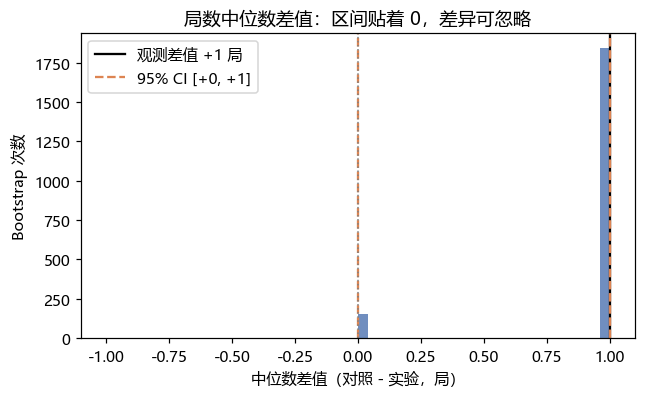

In [6]:
# 局数：中位数差值 + bootstrap 置信区间
med = bootstrap_diff(c.sum_gamerounds.to_numpy(), t.sum_gamerounds.to_numpy(),
                     n_boot=2000, seed=42)
print(med.summary())
print("CI 是否包含 0:", not med.ci_excludes_zero)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(med.boot_dist, bins=50, color="#4C72B0", alpha=0.8)
ax.axvline(med.observed, color="black", lw=1.5, label=f"观测差值 {med.observed:+.0f} 局")
ax.axvline(med.ci_low, color="#DD8452", ls="--", label=f"95% CI [{med.ci_low:+.0f}, {med.ci_high:+.0f}]")
ax.axvline(med.ci_high, color="#DD8452", ls="--")
ax.axvline(0, color="gray", ls=":", lw=1)
ax.set_xlabel("中位数差值（对照 - 实验，局）")
ax.set_ylabel("Bootstrap 次数")
ax.set_title("局数中位数差值：区间贴着 0，差异可忽略")
ax.legend()


中位数差 1 局，CI [0, 1]：**统计上贴着 0，业务上也可以忽略**。
注意 CI 很窄但端点全是整数——因为中位数是整数统计量，bootstrap 分布是离散的。
这种情况下"差值 = 1 局"到底算不算有意义，要靠业务判断，而不是再看一个 p 值。


In [7]:
# 反面教材：对局数均值做 Welch t 检验
tt = stats.ttest_ind(c.sum_gamerounds, t.sum_gamerounds, equal_var=False)
print(f"均值: 对照 {c.sum_gamerounds.mean():.1f} vs 实验 {t.sum_gamerounds.mean():.1f}")
print(f"t={tt.statistic:.3f}, p={tt.pvalue:.3f}  -> 不显著")
print()
print("但这个检验不可信：")
mean_c_drop = c.sum_gamerounds.sort_values().iloc[:-1].mean()
mean_t_drop = t.sum_gamerounds.sort_values().iloc[:-1].mean()
print(f"  去掉最大 1 人后均值: 对照 {mean_c_drop:.2f} vs 实验 {mean_t_drop:.2f}，"
      f"差 {mean_c_drop - mean_t_drop:+.2f} 局")
print(f"  原始均值差 {c.sum_gamerounds.mean() - t.sum_gamerounds.mean():+.2f} 局；"
      f"一个 49854 局的玩家把对照均值抬高了约 1.1 局")
print("  也就是说：均值差几乎全来自这一个人，t 检验的方差也被长尾撑大")


均值: 对照 52.5 vs 实验 51.3
t=0.885, p=0.376  -> 不显著

但这个检验不可信：
  去掉最大 1 人后均值: 对照 51.34 vs 实验 51.24，差 +0.10 局
  原始均值差 +1.16 局；一个 49854 局的玩家把对照均值抬高了约 1.1 局
  也就是说：均值差几乎全来自这一个人，t 检验的方差也被长尾撑大


**为什么这页要故意跑一个"错误"的检验**：面试官常问"为什么不用 t 检验比局数"，
你要能说出三点——长尾、均值被极值主导、正态假设不成立。跑一遍看到数字，比背结论记得牢。


## 3. 分层分析：效应是否一致？有没有辛普森悖论？

按累计局数分 5 桶，分别在桶内比较两组留存。要看的不是"每个桶显不显著"（桶内样本小、功效低），
而是**方向是否一致**、以及**加权后总差异会不会翻转**（辛普森悖论）。


In [8]:
bins = [-1, 0, 5, 20, 100, np.inf]
labels = ["0", "1-5", "6-20", "21-100", "100+"]
df["bin"] = pd.cut(df.sum_gamerounds, bins=bins, labels=labels)

rows = []
for b in labels:
    sub = df[df.bin == b]
    cc, tt = sub[sub.version == "gate_30"], sub[sub.version == "gate_40"]
    rc, rt = cc.retention_7.mean(), tt.retention_7.mean()
    lc, hc = wilson_interval(int(cc.retention_7.sum()), len(cc))
    lt, ht = wilson_interval(int(tt.retention_7.sum()), len(tt))
    rows.append({"桶": b, "n_对照": len(cc), "n_实验": len(tt),
                 "对照": rc, "实验": rt, "差(pp)": (rc - rt) * 100,
                 "对照CI下": lc, "对照CI上": hc, "实验CI下": lt, "实验CI上": ht})

table = pd.DataFrame(rows)
print(table.round(4).to_string(index=False))


     桶  n_对照  n_实验     对照     实验   差(pp)  对照CI下  对照CI上  实验CI下  实验CI上
     0  1937  2057 0.0083 0.0063  0.1940 0.0051 0.0134 0.0037 0.0108
   1-5 10119 10604 0.0129 0.0144 -0.1483 0.0109 0.0153 0.0123 0.0169
  6-20 12428 12657 0.0503 0.0475  0.2806 0.0466 0.0543 0.0439 0.0513
21-100 14121 13881 0.2393 0.2184  2.0933 0.2323 0.2464 0.2116 0.2253
  100+  6095  6290 0.7139 0.7124  0.1463 0.7024 0.7251 0.7011 0.7235


In [9]:
# 按对照组的结构做标准化（direct standardization）
w = table["n_对照"] / table["n_对照"].sum()
std_c = float((table["对照"] * w).sum())
std_t = float((table["实验"] * w).sum())
print(f"粗率:   对照 {p1:.2%} vs 实验 {p2:.2%}, 差 {(p1-p2)*100:+.3f}pp")
print(f"标准化: 对照 {std_c:.2%} vs 实验 {std_t:.2%}, 差 {(std_c-std_t)*100:+.3f}pp")
print("方向是否一致:", (std_c - std_t) > 0)


粗率:   对照 19.02% vs 实验 18.20%, 差 +0.820pp
标准化: 对照 19.02% vs 实验 18.29%, 差 +0.734pp
方向是否一致: True


标准化后差值从 0.82pp 变成 0.73pp，**方向不变、量级接近**：说明总差异不是"两组玩家结构不同"造成的，
不存在辛普森悖论式的翻转。

但注意：差异主要集中在 21-100 局这一桶（+2.1pp），其余桶接近 0。这提醒我们：
**平均效应可能只来自某类玩家**，报告里应该写清楚，而不是笼统说"提升了留存"。


In [10]:
# 交互检验：version 的效应在各桶是否一致
import statsmodels.formula.api as smf

d = df.rename(columns={"version": "grp"})
main = smf.logit("retention_7 ~ C(grp) + C(bin)", data=d).fit(disp=0)
inter = smf.logit("retention_7 ~ C(grp) * C(bin)", data=d).fit(disp=0)

lr = 2 * (inter.llf - main.llf)
df_diff = inter.df_model - main.df_model
p_inter = stats.chi2.sf(lr, df_diff)
print(f"LR={lr:.2f}, df={int(df_diff)}, p={p_inter:.3f}")
print("是否有异质性证据:", p_inter < 0.05)


LR=7.98, df=4, p=0.092
是否有异质性证据: False


p≈0.09 > 0.05：**没有足够证据说各桶效应不同**。所以"整体效应 +0.8pp"可以作为主结论，
但要在局限里注明"效应可能集中在中度玩家，样本不足以确认"。

顺带说明：分层变量是"实验后变量"，这里的分层是描述性分解，不是因果中介分析。


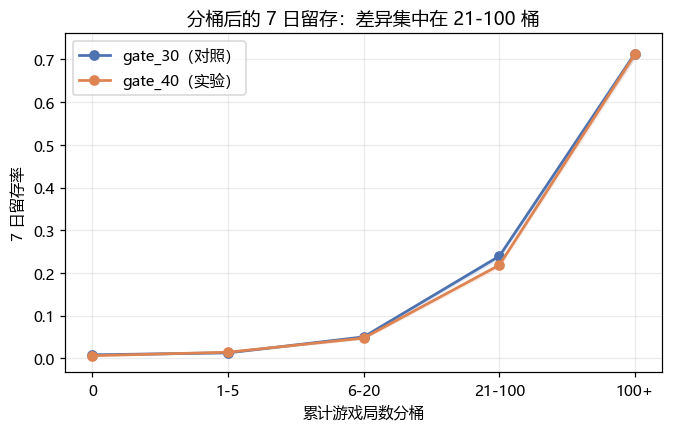

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(table))
for col, label, color in [("对照", "gate_30（对照）", "#4C72B0"), ("实验", "gate_40（实验）", "#DD8452")]:
    ax.plot(x, table[col], marker="o", label=label, color=color, lw=1.8)
    lo = table[f"{col}CI下"]
    hi = table[f"{col}CI上"]
    ax.fill_between(x, lo, hi, color=color, alpha=0.15, lw=0)
ax.set_xticks(x)
ax.set_xticklabels(table["桶"])
ax.set_xlabel("累计游戏局数分桶")
ax.set_ylabel("7 日留存率")
ax.set_title("分桶后的 7 日留存：差异集中在 21-100 桶")
ax.legend()
ax.grid(alpha=0.25)


## 4. 功效分析：这个实验"够不够用"

p 值回答"有没有证据"，功效回答"这个设计本来能不能看见证据"。三个常用量：

- **MDE（最小可检出效应）**：给定样本量和 α，80% 概率能检出的最小提升；
- **功效（power）**：给定真实效应，实验能显著的概率；
- **所需样本量**：想稳定检出某个效应，每组需要多少人。

注意：用"观测到的效应"反算功效是**事后功效**，只能当参考，不能拿来证明实验"足够"。


In [12]:
n_per_group = min(n1, n2)
base = p2  # 以实验组为基准
delta = abs(diff)

power_now = achieved_power(base, delta, n_per_group)
mde = min_detectable_delta(base, n_per_group)
print(f"每组 n={n_per_group:,}, 基准 {base:.2%}")
print(f"观测效应 {delta*100:.2f}pp 时的功效: {power_now:.1%}")
print(f"80% 功效的 MDE: {mde*100:.2f}pp")
print()
for target in [0.005, 0.01, 0.02]:
    need = int(round(required_sample_size(base, target)))
    print(f"想检出 {target*100:.1f}pp：每组需要 {need:,} 人（当前 {n_per_group:,}）")


每组 n=44,700, 基准 18.20%
观测效应 0.82pp 时的功效: 88.3%
80% 功效的 MDE: 0.73pp

想检出 0.5pp：每组需要 94,471 人（当前 44,700）
想检出 1.0pp：每组需要 23,862 人（当前 44,700）
想检出 2.0pp：每组需要 6,084 人（当前 44,700）


这组数字说明：**当前样本量对 1pp 以上的效应够用（只需 2.4 万人），对 0.5pp 不够（需要 9.4 万人）**。
本次观测到的 0.82pp 刚好在 MDE（0.73pp）附近，所以"显著"是合理的，但也接近设计边缘——
如果真实效应是 0.6pp，这次实验很可能漏掉。

**下次重做实验怎么设计**：先定"业务上值得改的最小提升"（比如 0.5pp），
按公式算样本量，再预留 10-20% 缓冲（分流损耗、SRM、异常用户）。


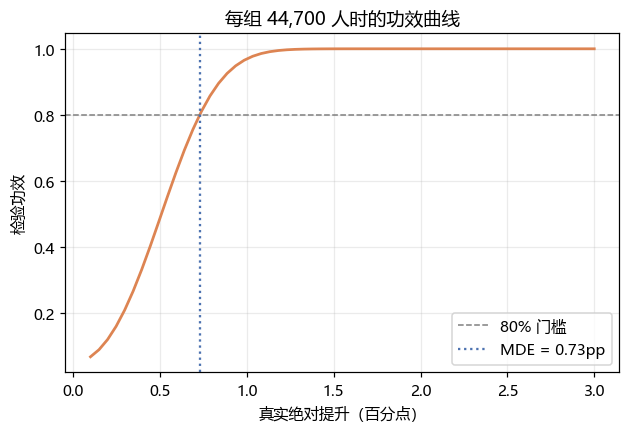

In [13]:
deltas = np.linspace(0.001, 0.03, 60)
powers = [achieved_power(base, d, n_per_group) for d in deltas]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(deltas * 100, powers, color="#DD8452", lw=1.8)
ax.axhline(0.8, ls="--", color="gray", lw=1, label="80% 门槛")
ax.axvline(mde * 100, ls=":", color="#4C72B0", label=f"MDE = {mde*100:.2f}pp")
ax.set_xlabel("真实绝对提升（百分点）")
ax.set_ylabel("检验功效")
ax.set_title("每组 44,700 人时的功效曲线")
ax.legend()
ax.grid(alpha=0.25)


**曲线怎么读**：横轴是"如果真实提升这么大"，纵轴是"这次实验能检出的概率"。
曲线在 0.73pp 处穿过 80%——比它小的效应，实验大概率看不见。

还有一个容易被忽略的点：**不能边跑边看、看到显著就停**（peeking）。
每多看一次就多一次假阳性机会，正确做法是事先固定样本量或使用序贯检验。


## 5. 汇总与决策

把关键数字整理成一张表，然后回答唯一重要的问题：**改不改门槛？**


In [14]:
summary = pd.DataFrame([
    {"指标": "7 日留存（主）", "对照": f"{p1:.2%}", "实验": f"{p2:.2%}",
     "差值": f"{diff*100:+.2f}pp", "95% CI": f"[{res.ci_low*100:+.2f}, {res.ci_high*100:+.2f}]pp",
     "p": f"{res.p_value:.4f}", "结论": "显著更高"},
    {"指标": "次日留存", "对照": f"{d1.p_control:.2%}", "实验": f"{d1.p_treatment:.2%}",
     "差值": f"{d1.diff*100:+.2f}pp", "95% CI": f"[{d1.ci_low*100:+.2f}, {d1.ci_high*100:+.2f}]pp",
     "p": f"{d1.p_value:.4f}", "结论": "不显著"},
    {"指标": "局数中位数", "对照": f"{c.sum_gamerounds.median():.0f}", "实验": f"{t.sum_gamerounds.median():.0f}",
     "差值": f"{med.observed:+.0f} 局", "95% CI": f"[{med.ci_low:+.0f}, {med.ci_high:+.0f}]",
     "p": "bootstrap", "结论": "可忽略"},
])
print(summary.to_string(index=False))


      指标     对照     实验      差值           95% CI         p   结论
7 日留存（主） 19.02% 18.20% +0.82pp [+0.31, +1.33]pp    0.0016 显著更高
    次日留存 44.82% 44.23% +0.59pp [-0.06, +1.24]pp    0.0744  不显著
   局数中位数     17     16    +1 局         [+0, +1] bootstrap  可忽略


### 决策：维持 gate_30

**理由**（三条，按重要性排序）：

1. 主指标显著更高，且 CI 下界 +0.31pp 仍为正——即使按最保守估计，改回 40 关也是净损失。
2. 没有证据显示短期体验受损（次日留存不显著、局数中位数无差异），不存在"用长期换短期"的迹象。
3. 效应量 0.82pp（相对 4.5%）在免费休闲游戏里不算小，按 10 万新增估算约多留 820 人。

**风险与前提**（必须写进报告）：

- 只有 14 天数据，7 日留存是短期指标；长期留存/付费可能不同，不能直接外推。
- SRM 未通过（p=0.009），虽然偏差只有 0.87%，仍需排查分流日志；若分流有系统性偏差，结论要打折扣。
- 效应集中在 21-100 局的中度玩家，样本不足以确认其他桶没有差异。

**如果业务坚持要上 40 关**：建议做一次更大样本、更长窗口的实验，主指标预注册为 7 日留存，
每组至少 9.4 万人（检出 0.5pp），并同时监控收入指标。

> 到这里，统计部分就完成了。接下来把数字变成一页纸：`python -m reports.make_one_pager`。
